# GEOG 592 — Week 9 Homework
## Cartography with Matplotlib

In [35]:
# https://www.gbif.org/

import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt



species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
year = 2025

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # 1. Find the GBIF taxon identifier for the scientific name.
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT"
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # 2. Define which occurrence records to request.
    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        # "stateProvince": "North Carolina",
        "year": year,
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    # 3. Retrieve successive pages of records.
    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        # LIMIT THE NUMBER OF CASES (you can chage it but, the larger the number...the longer the wait)
        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Narrow the date range or use a GBIF bulk download."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")


Vulpes vulpes: 6,204 records
Urocyon cinereoargenteus: 4,171 records


In [36]:
foxes = pd.DataFrame(records)
foxes = foxes[["queried_species", "decimalLongitude", "decimalLatitude"]] 
foxes.head()

,queried_species,decimalLongitude,decimalLatitude
0,Vulpes vulpes,-71.863675,44.461650
1,Vulpes vulpes,-77.285038,39.036542
2,Vulpes vulpes,-74.425279,40.458382
3,Vulpes vulpes,-77.252229,38.621250
4,Vulpes vulpes,-77.349752,38.937001


<Axes: >

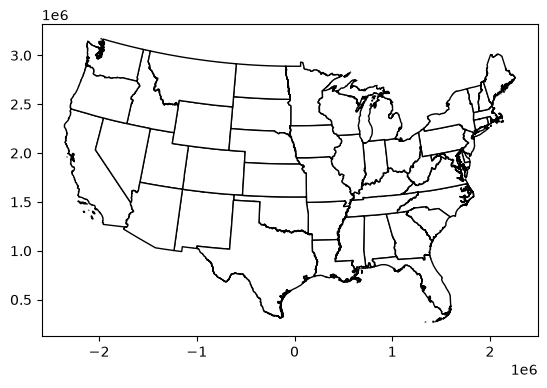

In [37]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


### Code for county level data 

# counties = gpd.read_file(url_0+url_county)
# nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
# nc_counties.plot(edgecolor="black", facecolor="white")

## remove Alaska, Hawaii and those other islands which makes mapping difficult, but life much nicer.  
states = gpd.read_file(url_0+url_state)
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
]

contiguous_us = contiguous_us.to_crs(epsg=5070)
contiguous_us.plot(edgecolor="black", facecolor="white")



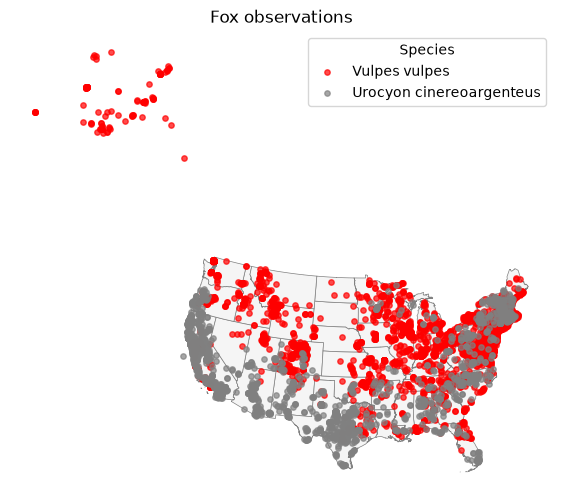

In [38]:

## make a gdp from the x and y data. 
fox_points = gpd.GeoDataFrame(
    foxes.copy(),
    geometry=gpd.points_from_xy( ## the method is calleed points_from_xy
        foxes["decimalLongitude"], # x
        foxes["decimalLatitude"] # y
        ),
    crs="EPSG:4326" # often the crs is in 4326 if it is a lat lon coordinate
    )

fox_points = fox_points.to_crs(epsg=5070)


fig, ax = plt.subplots(figsize=(12, 6))
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"}

for species, color in colors.items():
    fox_points.loc[
        fox_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Fox observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

In [39]:
# select points within contiguous states and keep the NAME of the state. 
points_by_state = gpd.sjoin(
    fox_points,
    contiguous_us[["NAME", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME
0,Vulpes vulpes,-71.863675,44.461650,POINT (1895265.228 2627757.285),Vermont
1,Vulpes vulpes,-77.285038,39.036542,POINT (1594618.45 1936529.956),Virginia
2,Vulpes vulpes,-74.425279,40.458382,POINT (1798508.726 2143364.206),New Jersey
3,Vulpes vulpes,-77.252229,38.621250,POINT (1606500.955 1891435.963),Virginia
4,Vulpes vulpes,-77.349752,38.937001,POINT (1591351.049 1924503.287),Virginia


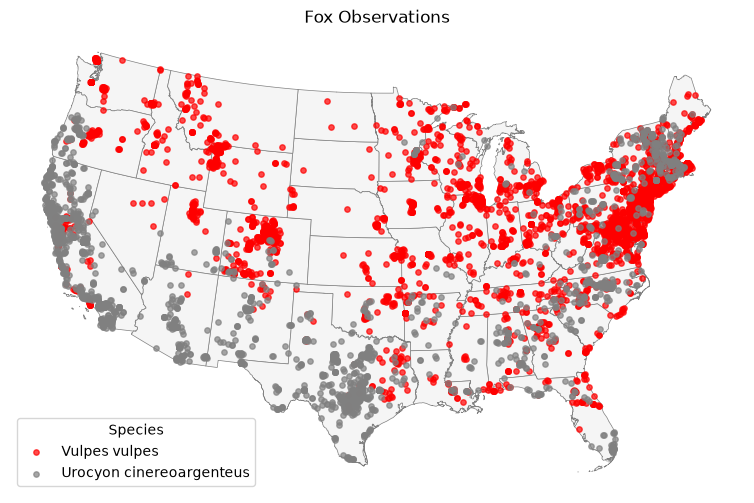

In [40]:
fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"} # making a dictionary 

for species, color in colors.items(): # 
    points_by_state.loc[
        points_by_state["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Fox Observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

In [41]:
def pointMap(ax):
    ### Plotting code suggested by AI

    # fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
    contiguous_us.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    colors = {"Vulpes vulpes": "red", "Urocyon cinereoargenteus": "gray"} # making a dictionary 

    for species, color in colors.items(): # 
        points_by_state.loc[
            points_by_state["queried_species"] == species
        ].plot(
            ax=ax,
            color=color,
            markersize=15,
            alpha=0.7,
            label=species
        )

    ax.set_title("Fox Observations")
    ax.legend(title="Species")
    ax.set_axis_off()
    return ax
  


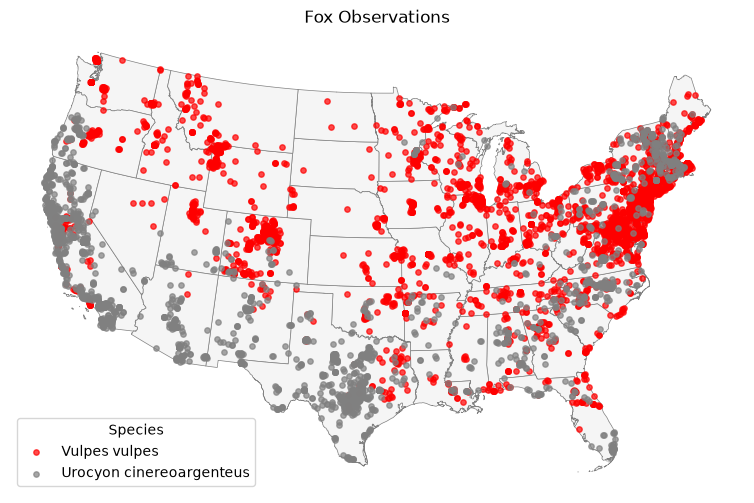

In [42]:
fig, ax = plt.subplots(figsize=(12, 6)) 
ax =  pointMap(ax)
plt.show()

In [43]:
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Vulpes vulpes", "Urocyon cinereoargenteus"], fill_value=0)
)

counts.head()

queried_species,Vulpes vulpes,Urocyon cinereoargenteus
NAME,,
Alabama,40,47
Arizona,2,151
Arkansas,43,18
California,104,1529
Colorado,326,22


In [44]:
def barPlot(ax, counts):
    counts = counts.loc[
        counts.sum(axis=1).sort_values(ascending=False).index
    ]

    counts[["Vulpes vulpes", "Urocyon cinereoargenteus"]].plot.bar(
        ax=ax,
        stacked=True,
        color=["firebrick", "gray"]
    )

    ax.set_xlabel("State")
    ax.set_ylabel("Number of observation records")
    ax.set_title("Red and gray fox observations by state")
    ax.legend(["Red fox", "Gray fox"])
    ax.tick_params(axis="x", labelrotation=90)

    return ax

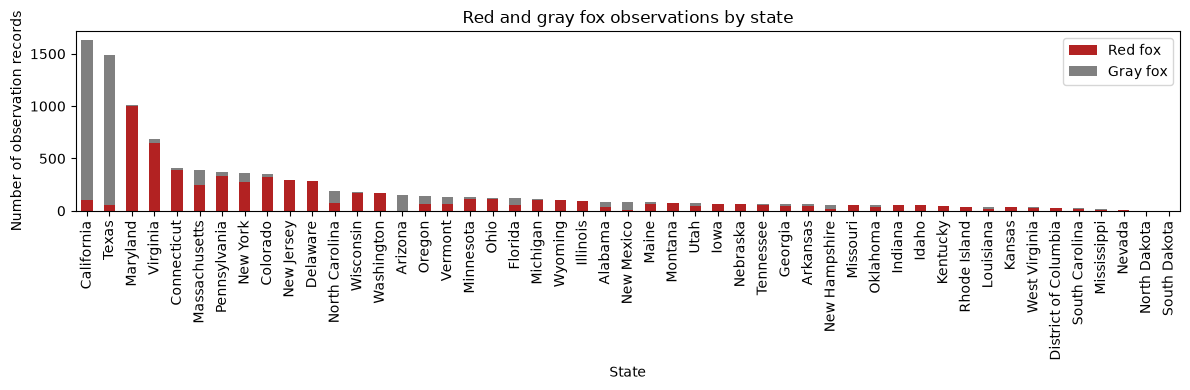

In [45]:
fig, ax = plt.subplots(figsize=(12, 4)) 
ax = barPlot(ax,counts)
fig.tight_layout()
plt.show()

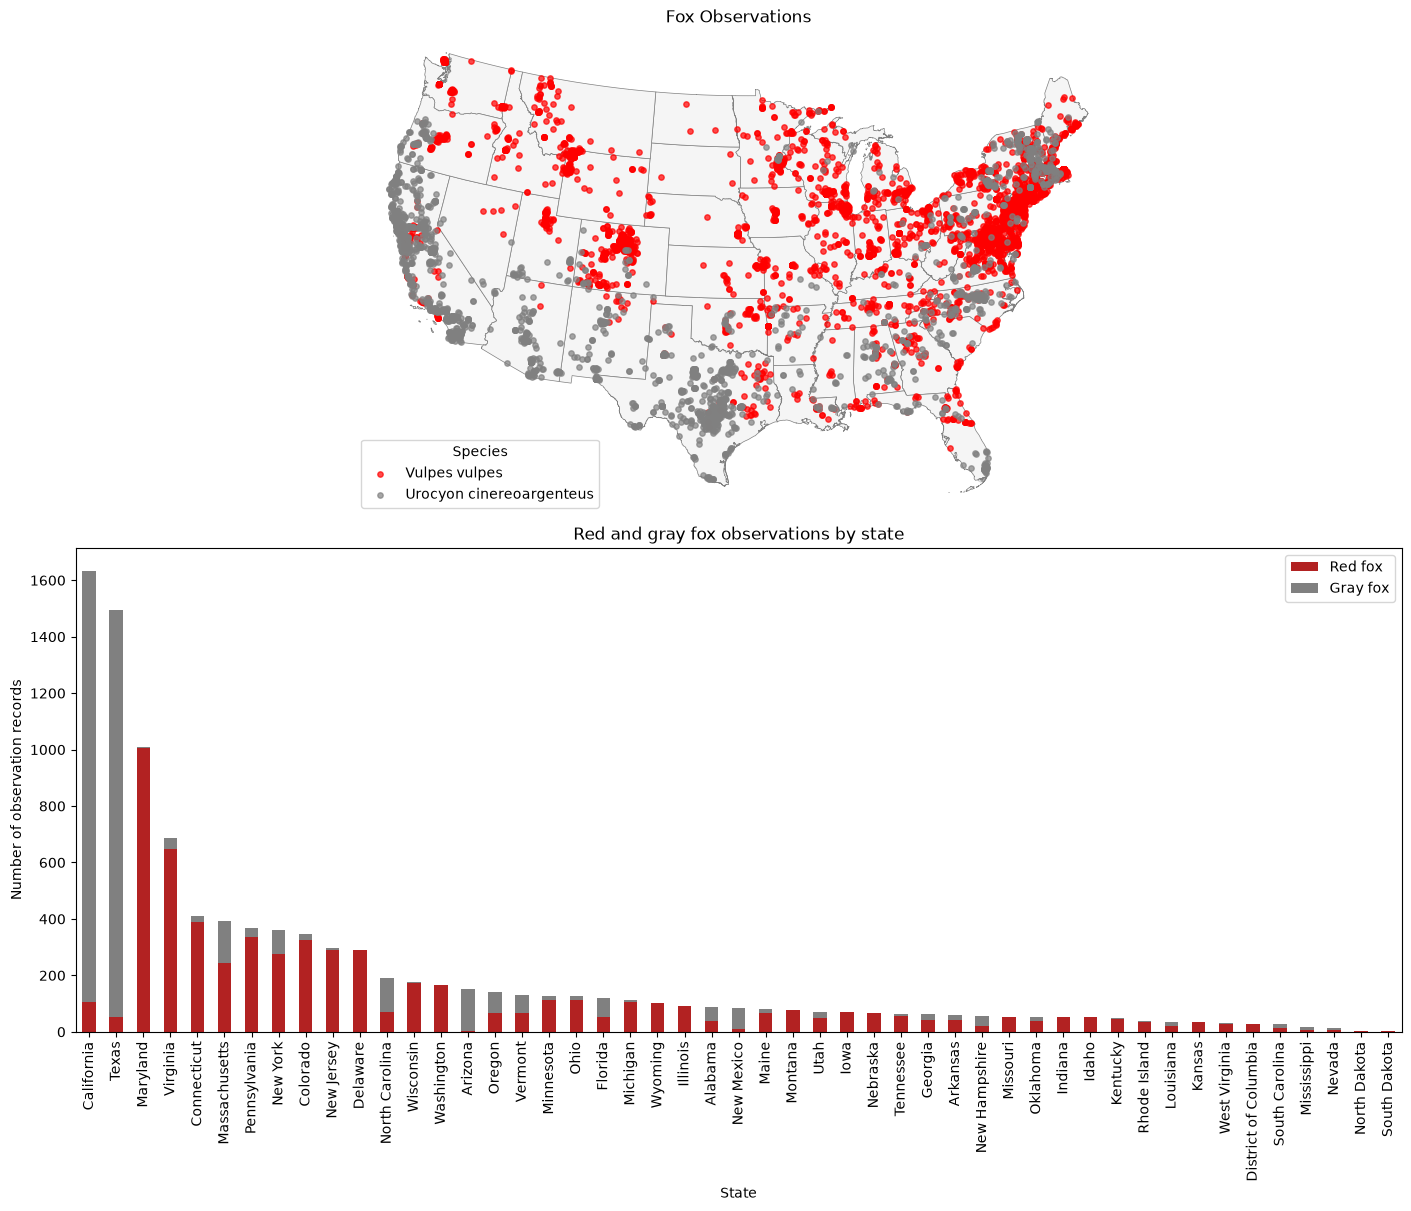

In [46]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 12),
    layout="constrained"
)

pointMap(axes[0])
barPlot(axes[1], counts)

plt.show()

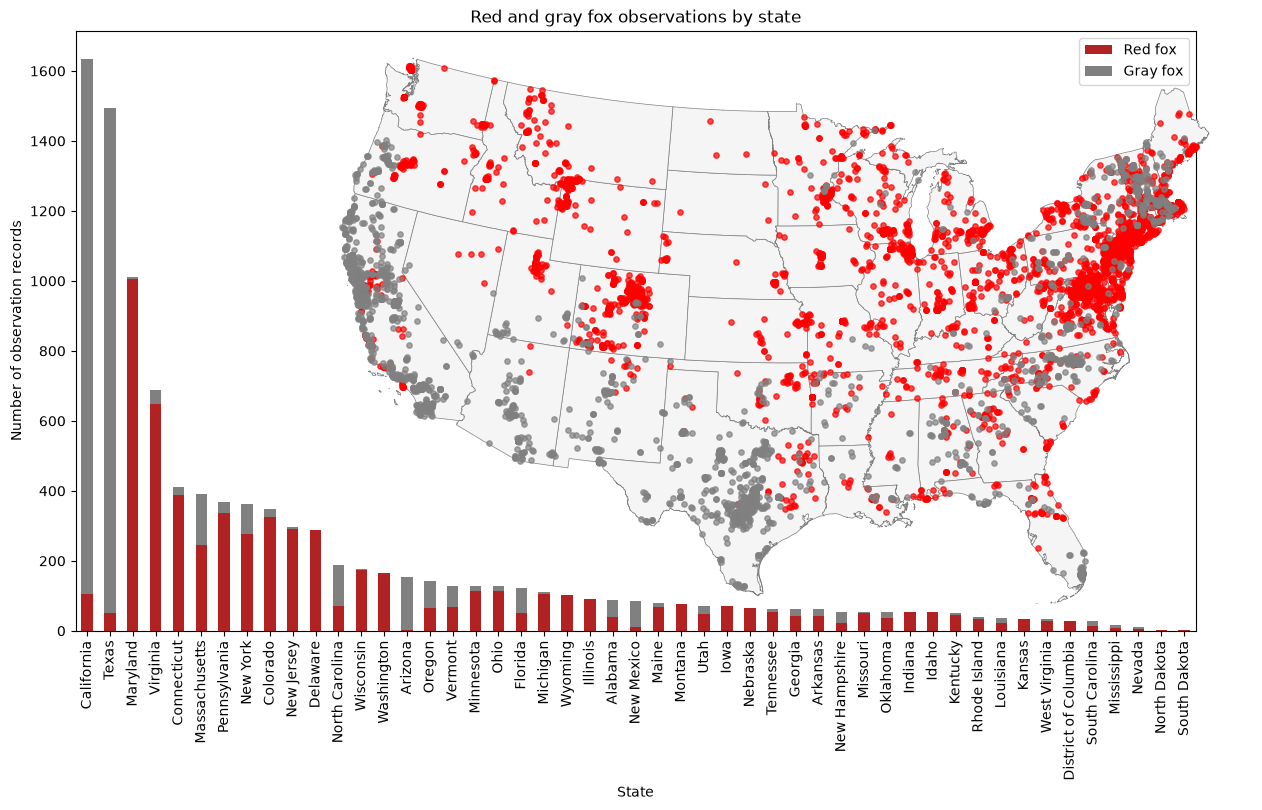

In [47]:
fig = plt.figure(figsize=(14, 8))

# [left, bottom, width, height], as fractions of the figure.
position_bar = [0.1, 0.15, 0.8, 0.75]
position_map= [0.20, 0.15, 0.8, 0.75]

ax_bar = fig.add_axes(position_bar, zorder=1)
barPlot(ax_bar, counts)

ax_map = fig.add_axes(position_map, zorder=2)
pointMap(ax_map)  # Match your function's arguments.

legend = ax_map.get_legend() # removing the legend
if legend is not None:
    legend.remove()

ax_map.set_title("") # removing the title 

# Make the upper layer transparent.
ax_map.set_facecolor("none")
ax_map.patch.set_alpha(0)
ax_map.set_axis_off()

plt.show()

In [48]:
# Made with AI

def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the state polygons.
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero.
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="YlOrRd", # This color was selected by me not Ai 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Fox observations by state")
    ax.set_axis_off()

    return ax

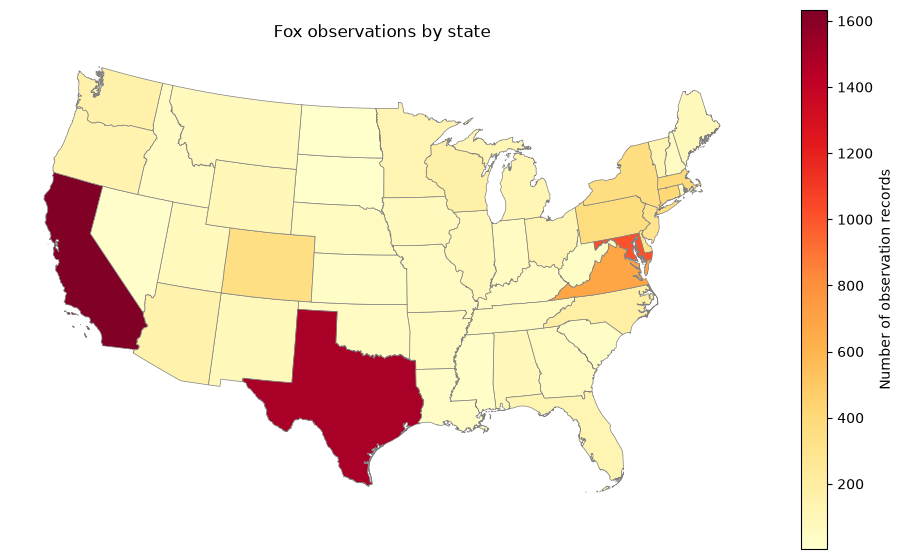

In [49]:
fig, ax = plt.subplots(figsize=(12, 7))

choroplethMap(ax, contiguous_us, counts)

plt.show()

# Choropleths

In [62]:
#%pip install mapclassify
## let's do some choropleths with classified data
import mapclassify


In [50]:
## code that I generated with AI to make the three different classification schemes

def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="YlOrRd",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


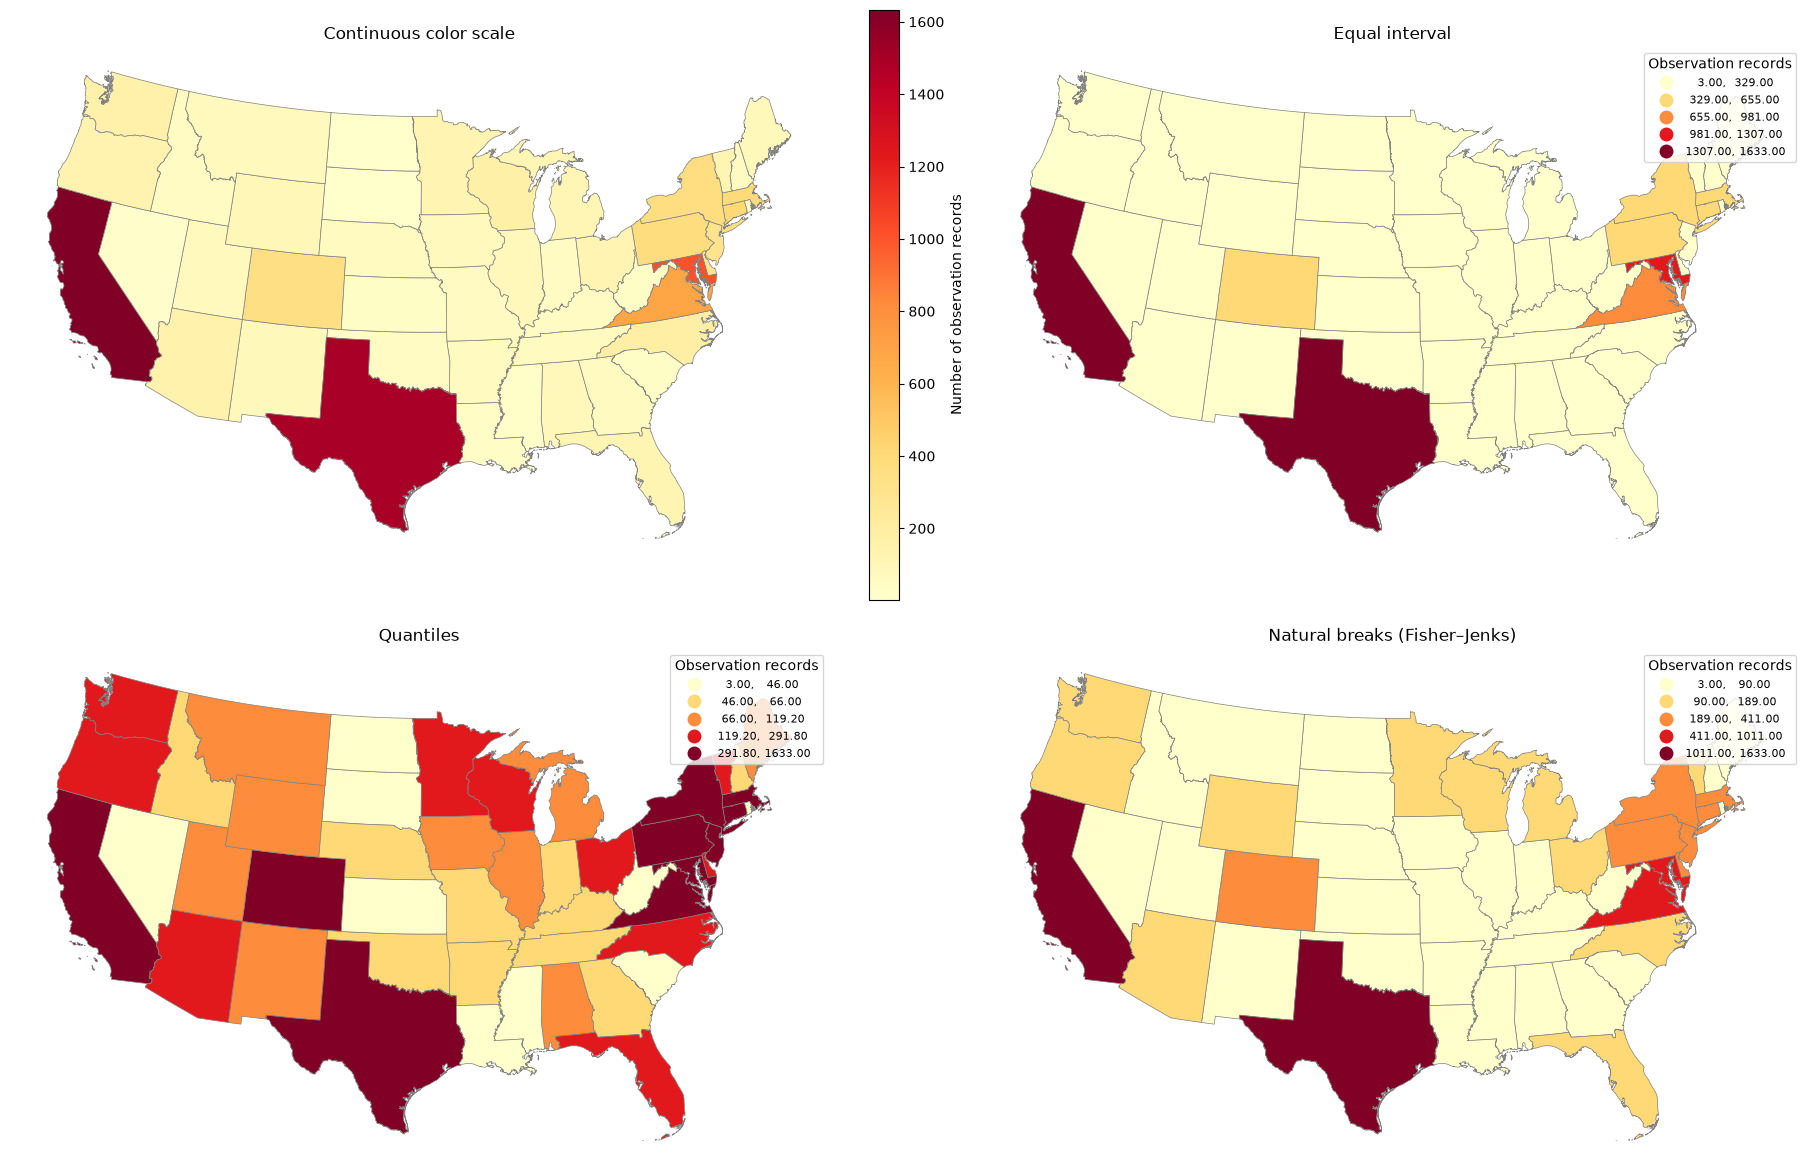

In [51]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], contiguous_us, counts)
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

plt.show()

In [52]:
# Export the figure as png
fig.savefig("fox_classification.png", dpi=300, bbox_inches="tight")
plt.show()

Vulpes vulpes positive-count median: 55.0
Urocyon cinereoargenteus positive-count median: 18.5


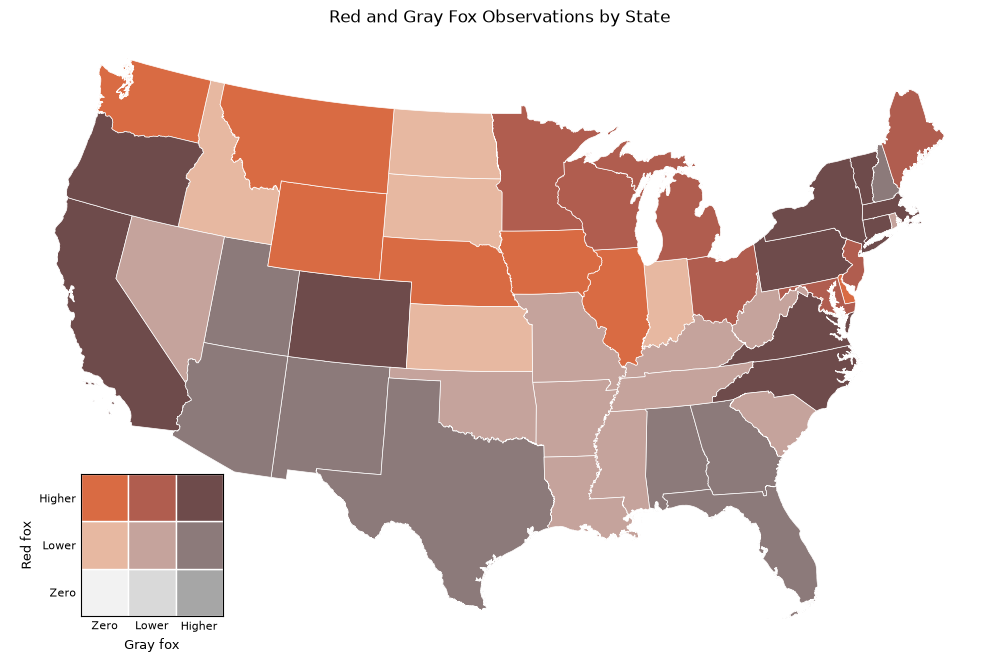

In [53]:
## Bivariate plot code generated using AI

import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# rows = Red fox class
# columns = Gray fox class
palette = np.array([
    ["#f2f2f2", "#d9d9d9", "#a6a6a6"],
    ["#e7b8a1", "#c5a39c", "#8c7a7a"],
    ["#d96b43", "#b05d4f", "#6e4b4b"]
])

bivariate["color"] = [
    palette[red_fox, gray_fox]
    for red_fox, gray_fox in zip(
        bivariate["Vulpes vulpes_class"],
        bivariate["Urocyon cinereoargenteus_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("Red and Gray Fox Observations by State")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red_fox in range(3):
    for gray_fox in range(3):
        legend_ax.add_patch(
            Rectangle(
                (gray_fox, red_fox), 1, 1,
                facecolor=palette[red_fox, gray_fox],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("Gray fox", fontsize=9)
legend_ax.set_ylabel("Red fox", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

In [54]:
# Export the figure as png
fig.savefig("fox_bivariate.png", dpi=300, bbox_inches="tight")
plt.show()

## Proportional Symbol Map

In [55]:
## First let's make sure that our statemap has the total mulberry counts 
totals = counts.sum(axis=1).rename("total")

state_map = contiguous_us.merge(
    totals, left_on="NAME", right_index=True, how="left"
)
state_map["total"] = state_map["total"].fillna(0)
state_map.head()

,STATEFP,STATENS,GEOIDFQ,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry,total
0,35,00897535,0400000US35,35,NM,New Mexico,00,314198519809,726531289,"POLYGON ((-1231344.076 1018550.43, -1231015.83...",85
1,46,01785534,0400000US46,46,SD,South Dakota,00,196341670967,3387563375,"POLYGON ((-633765.574 2472338.835, -633207.122...",3
2,06,01779778,0400000US06,06,CA,California,00,403673433805,20291632828,"MULTIPOLYGON (((-2066923.367 1403703.122, -206...",1633
3,21,01779786,0400000US21,21,KY,Kentucky,00,102266755818,2384136185,"MULTIPOLYGON (((584560.04 1518183.089, 585066....",50
4,01,01779775,0400000US01,01,AL,Alabama,00,131185561946,4581813708,"MULTIPOLYGON (((760323.731 857474.728, 760524....",87


In [56]:
# Then let's convert those polygons into points
centers = state_map.geometry.centroid
centers.head()

0       POINT (-920664.4 1309791.136)
1      POINT (-335519.731 2390919.81)
2    POINT (-2043268.577 1825251.386)
3       POINT (934451.28 1663329.213)
4      POINT (852665.426 1119782.502)
dtype: geometry

<Axes: >

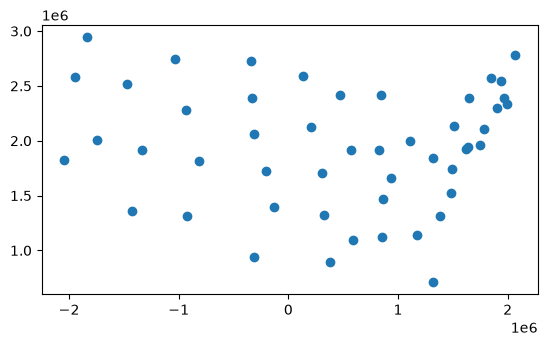

In [57]:
centers.plot()

In [58]:

# Let's make a map of the centroids and the states just to make sure that everything is looking ok
# Code partially done with Ai 

def pointMap(ax):

    # The state boundary map
    state_map.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )


    # The point map
    ax.scatter(
        centers.x,
        centers.y,
        s=state_map["total"], ## This is the magical line that is making a point map be a proportional size symbol
        color="#FF5349",
        alpha=0.6,
        edgecolors="white",
        linewidths=0.5
    )
    

    ax.legend(
        title="Observation records",
        loc="lower left",
        labelspacing=1.5
    )

    ax.set_title("Fox observations by state")
    ax.set_axis_off()

    return ax

/var/folders/zp/zh5prgyd61j54r9dpv3x1x_r0000gn/T/ipykernel_43753/4064957343.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


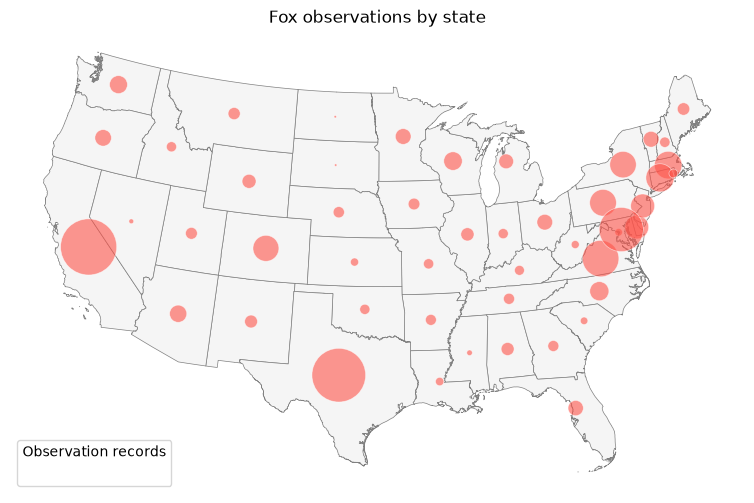

In [59]:
fig, ax = plt.subplots(figsize=(12, 6)) 
ax =  pointMap(ax)
plt.show()

In [60]:
#Code using AI

def propSymbol_class(ax):
    
    positive = state_map.loc[state_map["total"] > 0].copy()
    centers = positive.geometry.centroid

    classification = mapclassify.FisherJenks(
        positive["total"],
        k=3
    )

    # The state boundary map
    state_map.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    # Circle areas for low, medium, and high classes.
    sizes = np.array([60, 250, 700])

    ax.scatter(
        centers.x,
        centers.y,
        s=sizes[classification.yb],
        color="#FF5349",
        alpha=0.6,
        edgecolors="white",
        linewidths=0.5
    )

    # Build the legend using the actual count range in each class.
    for class_id, size in enumerate(sizes):
        values = positive.loc[
            classification.yb == class_id, "total"
        ]

        ax.scatter(
            [], [],
            s=size,
            color="#FF5349",
            alpha=0.6,
            edgecolors="white",
            label=f"{values.min():,.0f}–{values.max():,.0f}"
        )

    ax.legend(
        title="Observation records",
        loc="lower left",
        labelspacing=1.5
    )
    return ax

/var/folders/zp/zh5prgyd61j54r9dpv3x1x_r0000gn/T/ipykernel_43753/2073779003.py:2: UserWarning: Numba not installed. Using slow pure python version.
  ax =  propSymbol_class(ax)


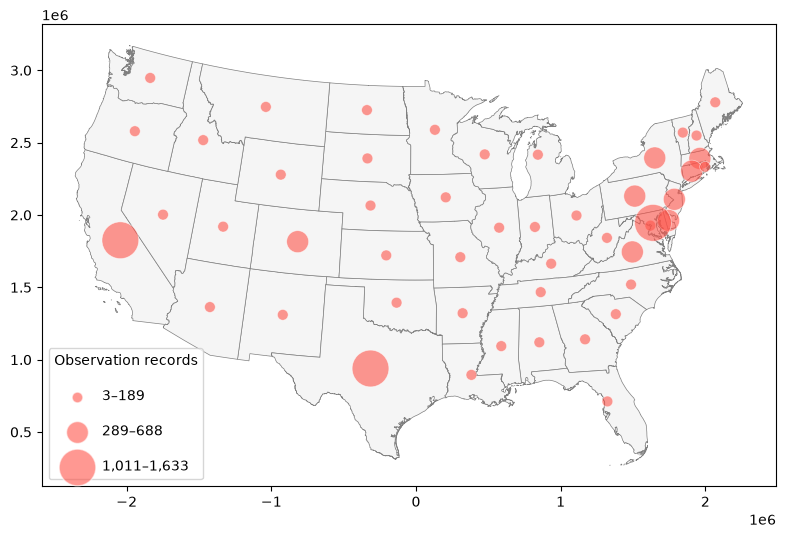

In [63]:
fig, ax = plt.subplots(figsize=(12, 6)) 
ax =  propSymbol_class(ax)
plt.show()

## Two Variable Symbology Map

In [83]:
### Code generated using AI 

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def pieMap(ax, contiguous_us, counts):
    species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
    colors = ["firebrick", "gray"]

    state_map = contiguous_us.to_crs(epsg=5070).merge(
        counts[species],
        left_on="NAME",
        right_index=True,
        how="left"
    )

    state_map[species] = state_map[species].fillna(0)
    state_map["total"] = state_map[species].sum(axis=1)

    positive = state_map.loc[state_map["total"] > 0].copy()

    # Three k-means classes, ordered from low to high.
    np.random.seed(42)
    classification = mapclassify.NaturalBreaks(
        positive["total"], k=3
    )
    positive["size_class"] = classification.yb

    state_map.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    # Preserve the map extent because ax.pie changes it.
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    radii = [40000, 80000, 120000]  # Map meters

    for _, state in positive.iterrows():
        center = state.geometry.centroid

        ax.pie(
            [state["Vulpes vulpes"], state["Urocyon cinereoargenteus"]],
            colors=colors,
            center=(center.x, center.y),
            radius=radii[int(state["size_class"])],
            startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 0.5}
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")

    # Species legend.
    species_legend = ax.legend(
        handles=[
            Patch(color=colors[0], label="Red fox"),
            Patch(color=colors[1], label="Gray fox")
        ],
        loc="lower left"
    )
    ax.add_artist(species_legend)

    # Convert map radii to legend marker diameters in points.
    ax.figure.canvas.draw()
    points_per_meter = (
        ax.get_window_extent().width
        / (xlim[1] - xlim[0])
        * 72 / ax.figure.dpi
    )

    handles = []
    for class_id, radius in enumerate(radii):
        values = positive.loc[
            positive["size_class"] == class_id, "total"
        ]

        handles.append(
            Line2D(
                [], [], linestyle="none", marker="o",
                markersize=2 * radius * points_per_meter,
                markerfacecolor="lightgray",
                markeredgecolor="gray",
                label=f"{values.min():,.0f}–{values.max():,.0f}"
            )
        )

    ax.legend(
        handles=handles,
        title="Records — three classes",
        loc="lower right",
        labelspacing=1.5
    )

    ax.set_title("Fox observations by state")
    ax.set_axis_off()
    return ax

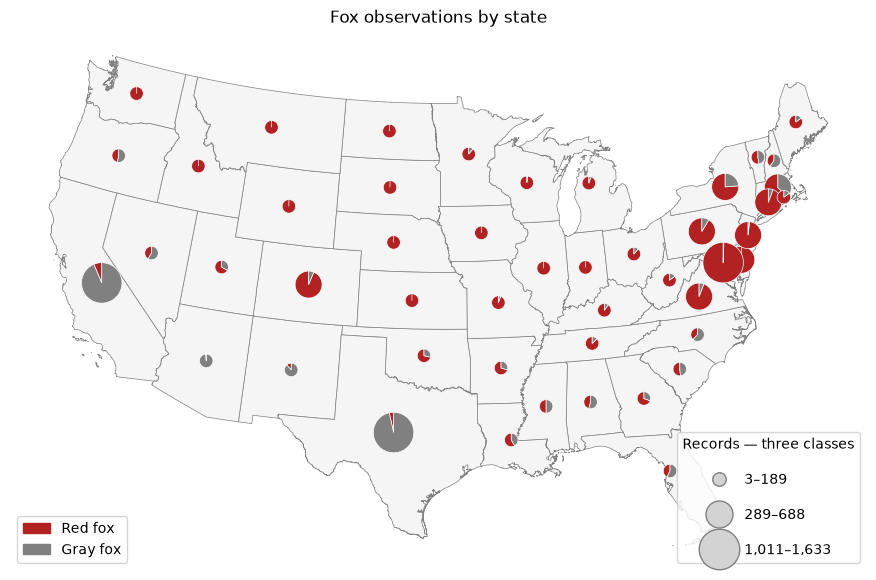

In [84]:
fig, ax = plt.subplots(figsize=(12, 7))

pieMap(ax, contiguous_us, counts)

plt.show()

In [85]:
# Export the figure as png
fig.savefig("fox_symbol.png", dpi=300, bbox_inches="tight")
plt.show()

## Hexagon Choropleth Map

In [86]:
from shapely.geometry import Polygon

# Equal-area projection with coordinates in meters.
states = contiguous_us
points = points_by_state.copy()

# Hexagon size: center to vertex, in meters.
radius = 100000

xmin, ymin, xmax, ymax = states.total_bounds
hexagons = []

for column, x in enumerate(
    np.arange(xmin - radius, xmax + 2 * radius, 1.5 * radius)
):
    for y in np.arange(
        ymin - radius, ymax + 2 * radius, np.sqrt(3) * radius
    ):
        # Offset alternating columns.
        center_y = y + (column % 2) * np.sqrt(3) * radius / 2

        angles = np.arange(6) * np.pi / 3

        hexagons.append(
            Polygon([
                (
                    x + radius * np.cos(angle),
                    center_y + radius * np.sin(angle)
                )
                for angle in angles
            ])
        )

grid = gpd.GeoDataFrame(
    {"hex_id": range(len(hexagons))},
    geometry=hexagons,
    crs=states.crs
)

# Keep hexagons that intersect the contiguous US.
region = states.geometry.union_all()
grid = grid.loc[grid.intersects(region)].copy()

# Assign each observation to a hexagon.
points = points.reset_index(drop=True)
points["point_id"] = points.index

joined = gpd.sjoin(
    points,
    grid[["hex_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

# Count an observation only once if it falls exactly on a shared edge.
joined = (
    joined.sort_values("hex_id")
    .drop_duplicates("point_id")
)

# Count records by hexagon and species.
hex_counts = (
    joined.groupby(["hex_id", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Vulpes vulpes", "Urocyon cinereoargenteus"], fill_value=0)
)

grid = grid.merge(
    hex_counts,
    left_on="hex_id",
    right_index=True,
    how="left"
)

species = ["Vulpes vulpes", "Urocyon cinereoargenteus"]
grid[species] = grid[species].fillna(0)
grid["total"] = grid[species].sum(axis=1)

<Axes: >

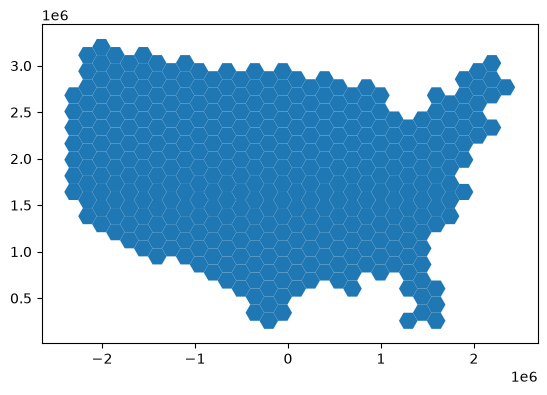

In [87]:
# Let's look at that heaxgon grid
grid.plot() 

In [88]:
# Code generated using AI 

def hexCountMap(ax, grid, states):
    grid.plot(
        ax=ax,
        column="total",
        cmap="YlOrRd",
        edgecolor="white",
        linewidth=0.2,
        legend=True,
        legend_kwds={"label": "Number of observation records"}
    )

    states.boundary.plot(
        ax=ax,
        color="gray",
        linewidth=0.4
    )

    ax.set_title("Fox observations per hexagon")
    ax.set_axis_off()
    return ax

In [89]:
# Code generated using AI 

from matplotlib.patches import Rectangle

def hexBivariateMap(ax, grid, states):
    mapped = grid.copy()

    for name in ["Vulpes vulpes", "Urocyon cinereoargenteus"]:
        values = mapped[name]
        median = values.loc[values > 0].median()

        mapped[name + "_class"] = np.select(
            [values == 0, values <= median],
            [0, 1],
            default=2
        )

    # Rows: increasing red mulberry.
    # Columns: increasing white mulberry.
    palette = np.array([
        ["#f2f2f2", "#d9d9d9", "#a6a6a6"],
        ["#e7b8a1", "#c5a39c", "#8c7a7a"],
        ["#d96b43", "#b05d4f", "#6e4b4b"]
    ])

    mapped["color"] = [
        palette[red, white]
        for red, white in zip(
            mapped["Vulpes vulpes_class"],
            mapped["Urocyon cinereoargenteus_class"]
        )
    ]

    mapped.plot(
        ax=ax,
        color=mapped["color"],
        edgecolor="white",
        linewidth=0.2
    )

    states.boundary.plot(ax=ax, color="gray", linewidth=0.4)

    legend_ax = ax.inset_axes([0.05, 0.05, 0.18, 0.23])

    for red in range(3):
        for white in range(3):
            legend_ax.add_patch(
                Rectangle(
                    (white, red), 1, 1,
                    facecolor=palette[red, white],
                    edgecolor="white"
                )
            )

    legend_ax.set_xlim(0, 3)
    legend_ax.set_ylim(0, 3)
    legend_ax.set_aspect("equal")
    legend_ax.set_xticks([0.5, 1.5, 2.5])
    legend_ax.set_yticks([0.5, 1.5, 2.5])
    legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_xlabel("Gray fox", fontsize=8)
    legend_ax.set_ylabel("Red fox", fontsize=8)
    legend_ax.tick_params(length=0)

    ax.set_title("Red and gray fox observations")
    ax.set_axis_off()
    return ax

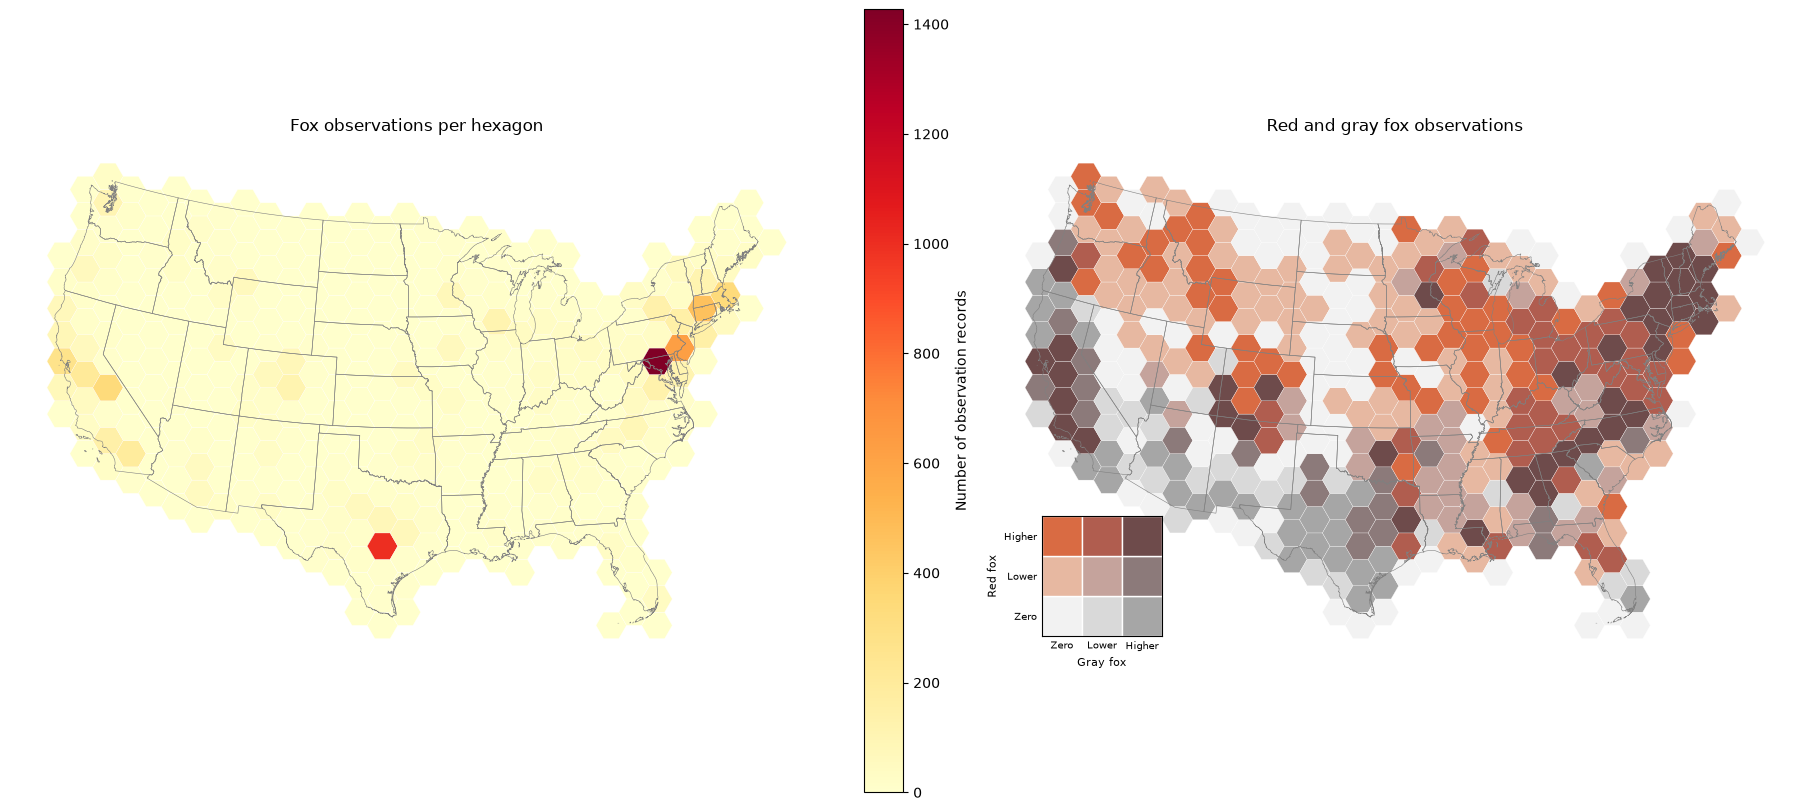

In [90]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    layout="constrained"
)

hexCountMap(axes[0], grid, states)
hexBivariateMap(axes[1], grid, states)

plt.show()

## Log Scale

In [91]:
from matplotlib.colors import LogNorm

def hexCountMapLog(ax, grid, states):
    grid.plot(
        ax=ax,
        facecolor="lightgray",
        edgecolor="white",
        linewidth=0.2
    )

    positive = grid.loc[grid["total"] > 0]

    if not positive.empty:
        positive.plot(
            ax=ax,
            column="total",
            cmap="YlOrRd",
            norm=LogNorm(
                vmin=1,
                vmax=max(2, positive["total"].max())
            ),
            edgecolor="white",
            linewidth=0.2,
            legend=True,
            legend_kwds={"label": "Observation records (log scale)"}
        )

    # states.boundary.plot(ax=ax, color="gray", linewidth=0.4)

    ax.set_title("Fox observations per hexagon")
    ax.set_axis_off()
    return ax

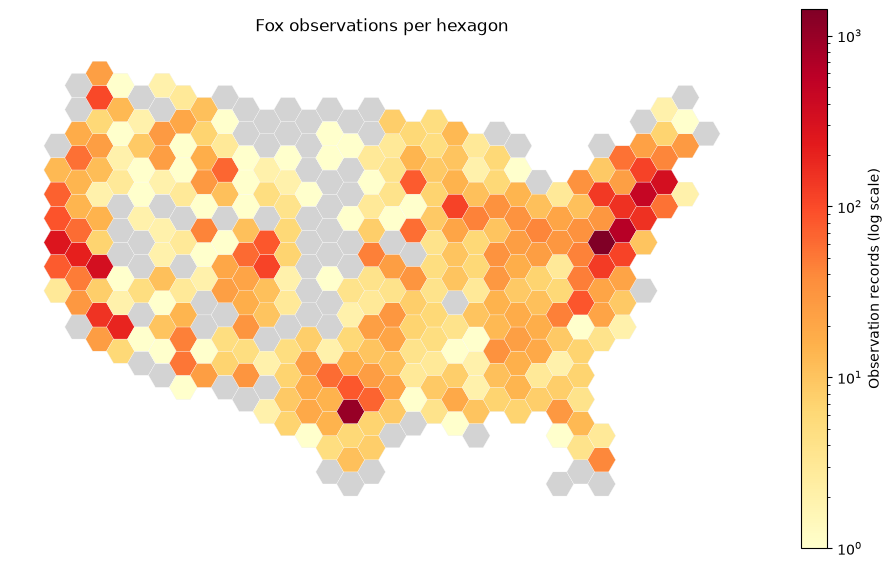

In [92]:
fig, ax = plt.subplots(figsize=(12, 7))

hexCountMapLog(ax, grid, states)

plt.show()

In [93]:
# Export the figure as png
fig.savefig("fox_hexagon.png", dpi=300, bbox_inches="tight")
plt.show()

## AI Usage
**General Error Help**\
Had some errors due to uninstalled packages and needed program updates, so AI helped clarify which needed to be installed and how to update my general Python system.

**Color Selection**\
The class example code used red and purple colors which I did not think depicted the gray and red foxes very well, so I used AI to help select the colors in the bivariate maps that work work better for those species. 